# 6. Восстановление фаз пространственного поля

Поле зависит от двух углов $\theta_1,\theta_2$. Полный оборот любого из них возвращает поле к прежнему состоянию, если второй угол фиксирован.

Наблюдаем показания датчиков и строим по ним окна. Ищем на облаке окон две угловые координаты:

$$\theta_n\ \longrightarrow\ y_n\ \longrightarrow\ h_n\
\longrightarrow\bigl(\phi_1(h_n),\phi_2(h_n)\bigr).$$

Если окна различают положения обеих фаз, их периодичность может сохраниться в геометрии облака. Найденные углы не обязаны совпасть с $\theta_1,\theta_2$: они могут описывать смеси или обертоны. Поэтому отдельно проверяем, какие физические фазы они отслеживают.

In [1]:
import sys
import json
import hashlib
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
from scipy.linalg import eigh
from matplotlib.collections import PolyCollection

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents]
            if (p / "code/lag_ssa/geometric_phase_frontend.py").exists())
sys.path.insert(0, str(ROOT / "code/lag_ssa"))

from nodal_spatial import NodalSpatialModel
from run_geometric_phase_frontend import build_hankel_blocks, SETTINGS as WINDOW_SETTINGS
from geometric_phase_frontend import SETTINGS, fit_hankel_topology, frozen_arrays
from geometric_phase_encoding import encode_hankel_blocks

FIXTURES = ROOT / "notebooks/fixtures/06_phase_ssa"
FIGURES = ROOT / "results/notebooks/06_phase_ssa"
FIGURES.mkdir(parents=True, exist_ok=True)
N_TRAIN = WINDOW_SETTINGS.n_train
L = WINDOW_SETTINGS.lag_window
Q = SETTINGS.averaging_window

plt.rcParams.update({"figure.dpi": 120, "font.size": 10,
                     "axes.spines.top": False, "axes.spines.right": False})

def load_npz(path):
    with np.load(path, allow_pickle=False) as archive:
        return {key: archive[key] for key in archive.files}

def show_figure(fig, name):
    fig.savefig(FIGURES / f"{name}.png", dpi=140, bbox_inches="tight")
    plt.show()
    plt.close(fig)

## 1. Наблюдения

$$Y_{in}=F(s_i,\theta_n)+\varepsilon_{in}.$$

$p$ — число датчиков, $N$ — число обучающих отсчётов.

$Y_{in}$ — показание датчика $i$ в момент $n$; $s_i$ — его положение; $\theta_n=(\theta_{1n},\theta_{2n})$ — скрытые фазы, каждая по модулю $2\pi$; $F$ — неизвестное поле; $\varepsilon_{in}$ — шум.

В двух примерах по 10 датчиков и две фазы. Датчики расположены на прямой или на плоскости. Шум составляет 8% среднеквадратичного уровня чистого сигнала.

Сверху показано расположение датчиков, снизу — их записи. Первые 2400 отсчётов используем для обучения, последние 1200 — для проверки; между ними 1200 промежуточных отсчётов. Истинные фазы не участвуют в построении углов. При оценке качества они нужны для совмещения начала отсчёта на обучении и вычисления ошибки на проверке.

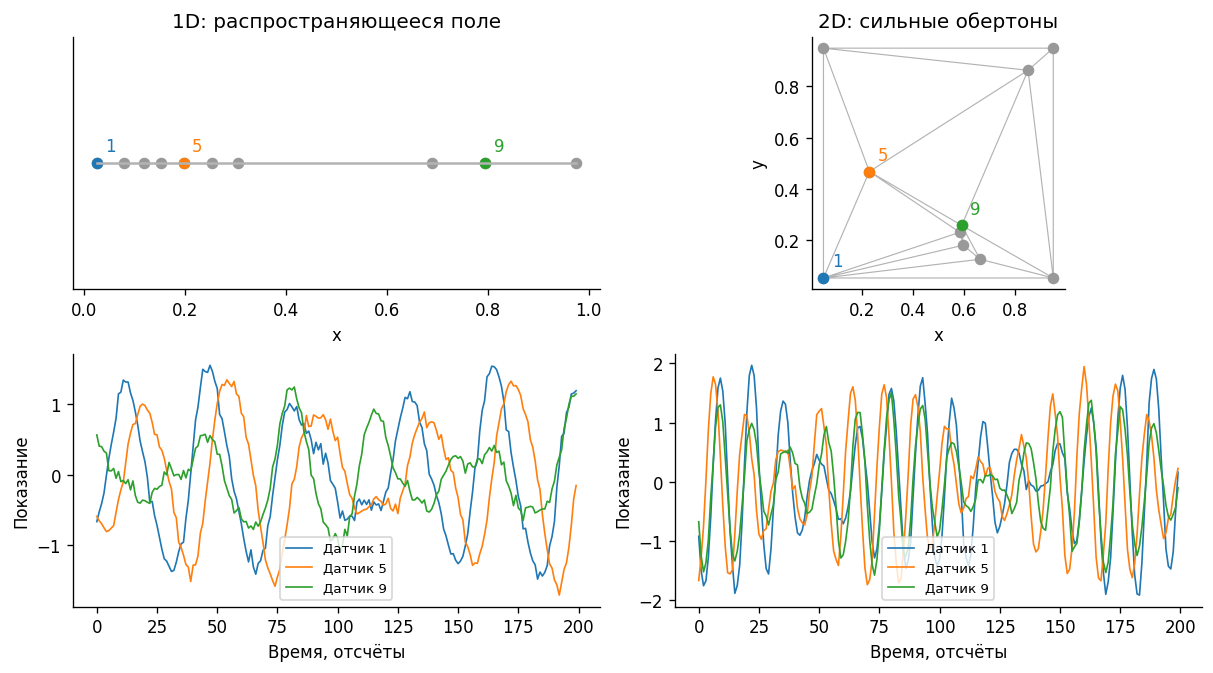

In [2]:
names = ["fresh_r2_irrational_travelling_1d", "fresh_r2_primitive_cover6"]
labels = ["1D: распространяющееся поле", "2D: сильные обертоны"]
data = {name: load_npz(FIXTURES / f"{name}.npz")
        for name in names}
spatial = {name: NodalSpatialModel.from_positions(data[name]["s"]) for name in names}

fig, axes = plt.subplots(2, 2, figsize=(10, 5.5), layout="constrained")
for col, (name, label) in enumerate(zip(names, labels)):
    Y, s, t = (data[name][key] for key in ("Y", "s", "t"))
    ax = axes[0, col]
    if s.shape[1] == 1:
        ax.plot(np.sort(s[:, 0]), np.zeros(len(s)), color="0.7")
        ax.scatter(s[:, 0], np.zeros(len(s)), s=35, color="0.6")
        ax.set(xlabel="x", yticks=[], ylim=(-.15, .15), title=label)
    else:
        ax.triplot(s[:, 0], s[:, 1], spatial[name].cells, color="0.7", lw=.7)
        ax.scatter(*s.T, s=35, color="0.6")
        ax.set(xlabel="x", ylabel="y", aspect="equal", title=label)
    for i, color in zip((0, 4, 8), ("C0", "C1", "C2")):
        point = (s[i, 0], 0) if s.shape[1] == 1 else s[i]
        ax.scatter(*point, s=35, color=color)
        ax.annotate(str(i + 1), point, xytext=(5, 7), textcoords="offset points", color=color)
        axes[1, col].plot(t[:200], Y[i, :200], lw=1, color=color, label=f"Датчик {i + 1}")
    axes[1, col].set(xlabel="Время, отсчёты", ylabel="Показание")
    axes[1, col].legend(fontsize=8)
show_figure(fig, "01_sensors_and_records")

## 2. Пространственные веса

$v_i$ — показание датчика $i$. Между датчиками интерполируем значения линейно:

$$f_v(s)=\sum_i v_i b_i(s)$$
$$(M_s)_{ij}=\int b_i(s)b_j(s)\,ds,\qquad M_s\in\mathbb R^{p\times p}$$

$b_i$ равно 1 в датчике $i$ и 0 в остальных. На отрезке от 0 до 1 две функции равны $b_1(x)=1-x$, $b_2(x)=x$. Поэтому

$$M_{11}=\int_0^1(1-x)^2dx=\frac13,\qquad
M_{12}=\int_0^1x(1-x)\,dx=\frac12-\frac13=\frac16,\qquad
M_{22}=\int_0^1x^2dx=\frac13.$$

Отрезок длины $\ell$ даёт матрицу

$$M^{[i,j]}=\frac{\ell}{6}
\begin{pmatrix}2&1\\1&2\end{pmatrix}.$$

Её элементы прибавляем в строки и столбцы $i,j$ общей матрицы. На рисунке три датчика с расстояниями 1. Средний входит в два отрезка: его диагональный элемент равен $2/6+2/6=4/6$.

Для трёх датчиков в точках $0,1,2$ получается

$$M_s=\begin{pmatrix}
\frac13&\frac16&0\\
\frac16&\frac23&\frac16\\
0&\frac16&\frac13
\end{pmatrix}
=\frac16\begin{pmatrix}2&1&0\\1&4&1\\0&1&2\end{pmatrix}.$$

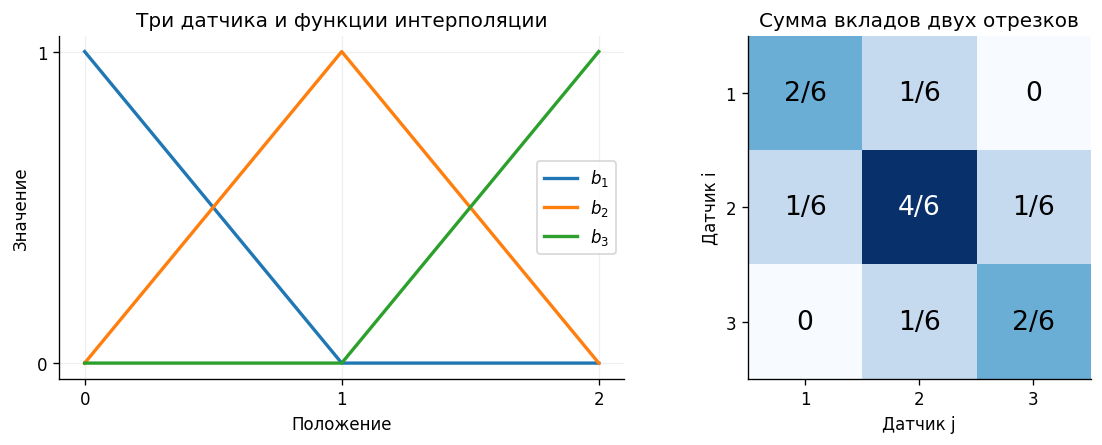

In [3]:
example_positions = np.array([[0.], [1.], [2.]])
example_mass = NodalSpatialModel.from_positions(example_positions).physical_mass
np.testing.assert_allclose(example_mass, np.array([[2, 1, 0], [1, 4, 1], [0, 1, 2]])/6)
fig, axes = plt.subplots(1, 2, figsize=(10, 3.6), layout="constrained")
x = np.linspace(0, 2, 301)
for i in range(3):
    basis = np.interp(x, example_positions[:, 0], np.eye(3)[i])
    axes[0].plot(x, basis, lw=2, label=f"$b_{i+1}$")
axes[0].set(title="Три датчика и функции интерполяции",
            xlabel="Положение", ylabel="Значение", xticks=[0, 1, 2], yticks=[0, 1])
axes[0].legend()
axes[0].grid(alpha=.2)
axes[1].imshow(example_mass, cmap="Blues", vmin=0, vmax=4/6)
for i in range(3):
    for j in range(3):
        numerator = int(round(6*example_mass[i, j]))
        label = f"{numerator}/6" if numerator else "0"
        axes[1].text(j, i, label, ha="center", va="center", fontsize=16,
                     color="white" if numerator >= 3 else "black")
axes[1].set(title="Сумма вкладов двух отрезков",
            xlabel="Датчик j", ylabel="Датчик i",
            xticks=range(3), xticklabels=[1, 2, 3],
            yticks=range(3), yticklabels=[1, 2, 3])
show_figure(fig, "02_mass_construction")

В 2D сетка состоит из треугольников. На треугольнике $x,y\ge0$, $x+y\le1$ функции равны $1-x-y$, $x$, $y$, а площадь $A=1/2$. Например,

$\int_0^1\int_0^{1-x}xy\,dy\,dx=\frac1{24}=\frac A{12}.$

Для любого треугольника площади $A$ получаем

$$\int b_i^2\,ds=\frac A6,\qquad
\int b_i b_j\,ds=\frac A{12}\quad(i\ne j),\qquad
M^{[i,j,k]}=\frac A{12}
\begin{pmatrix}2&1&1\\1&2&1\\1&1&2\end{pmatrix}.$$

Как и в 1D, складываем вклады в строки и столбцы соответствующих датчиков.

## 3.корень 

Сравниваем интерполированные поля по всей области, учитывая расстояния между датчиками:

$$\int |f_v(s)|^2ds=v^\mathsf{T}M_s v.$$

Обычная длина вектора даёт эту величину после преобразования $z=Rv$:

$$R=M_s^{1/2},\qquad R^\mathsf{T}R=M_s,\qquad
\|Rv\|^2=v^\mathsf{T}M_s v.$$

Это квадратный корень **матрицы**, не каждого её элемента. Одно показание может соответствовать разным положениям колебания: например, $\cos\theta=\cos(-\theta)$. История помогает их различить. Объединяем $L$ последовательных показаний в окно $h_n\in\mathbb R^{pL}$:

$$h_n=\frac1{\sqrt L}
\begin{pmatrix}
R(y_{n-L+1}-\bar y)\\
\vdots\\
R(y_n-\bar y)
\end{pmatrix}.$$

$y_n\in\mathbb R^p$ — показания всех датчиков, $\bar y$ — среднее по обучению. Деление на $\sqrt L$ усредняет квадрат нормы по окну. Ниже — одно окно до взвешивания.

Квадрат расстояния между окнами — средний по времени квадрат пространственной разницы полей:

$$\|h_n-h_m\|^2=\frac1L\sum_{a=0}^{L-1}
(y_{n-a}-y_{m-a})^\mathsf{T}M_s(y_{n-a}-y_{m-a}).$$

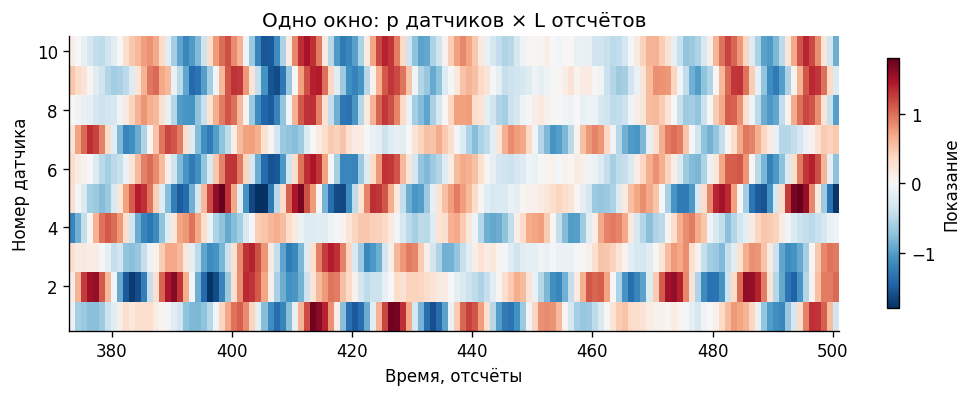

In [4]:
blocks = {}
for name in names:
    Y = data[name]["Y"]
    case = dict(Y=Y, times=data[name]["t"],
                mean_sensor_train=Y[:, :N_TRAIN].mean(axis=1),
                mass_sqrt=spatial[name].mass_sqrt)
    blocks[name] = build_hankel_blocks(case)

name = names[1]
last = 500
fig, ax = plt.subplots(figsize=(8, 3.2), layout="constrained")
im = ax.imshow(data[name]["Y"][:, last-L+1:last+1],
               aspect="auto", origin="lower", cmap="RdBu_r",
               extent=(last-L+1, last+1, .5, 10.5))
ax.set(title="Одно окно: p датчиков × L отсчётов",
       xlabel="Время, отсчёты", ylabel="Номер датчика")
fig.colorbar(im, ax=ax, shrink=.85, label="Показание")
show_figure(fig, "02_windows_and_mass")

## 4. Облако окон

Из $N$ обучающих отсчётов получаем $K=N-L+1$ окон:

$$H=(h_{L-1},\ldots,h_{N-1})\in\mathbb R^{pL\times K}.$$

Каждый столбец — точка пространства $\mathbb R^{pL}$. На рисунке показана трёхмерная проекция; цвет обозначает время. Расстояния вычисляем в исходном пространстве окон.


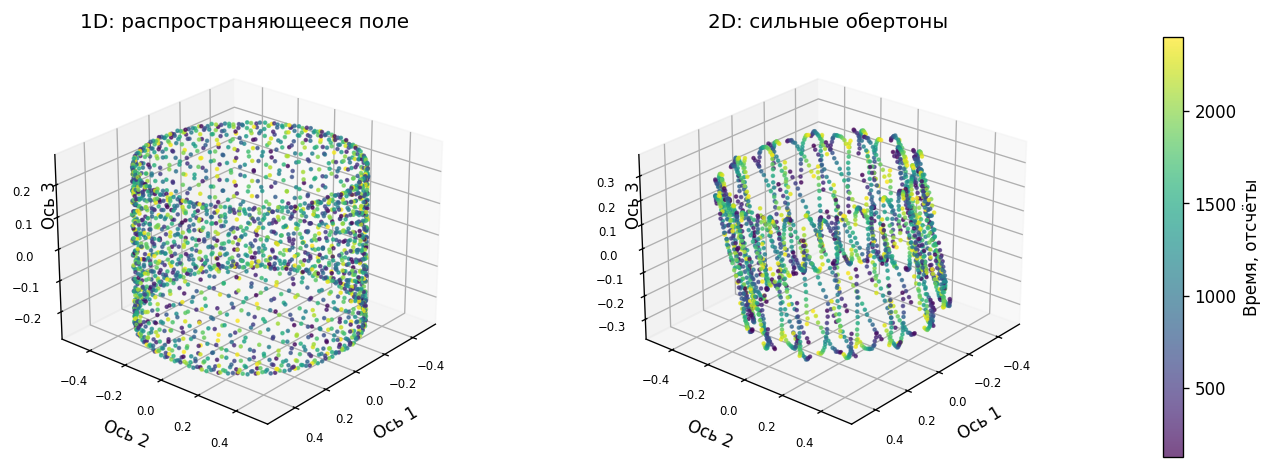

In [5]:
fig = plt.figure(figsize=(11, 4.6))
grid = fig.add_gridspec(1, 3, width_ratios=[1, 1, .04],
                        left=.04, right=.94, bottom=.12, top=.88, wspace=.25)
for col, name in enumerate(names):
    H = blocks[name]["train"]["H"]
    centered = H - H.mean(axis=1, keepdims=True)
    covariance = np.einsum("ik,jk->ij", centered, centered, optimize=False)
    _, U = eigh(covariance, subset_by_index=[len(H)-3, len(H)-1])
    projection = np.einsum("ij,ik->kj", centered, U[:, ::-1], optimize=False)
    ax = fig.add_subplot(grid[0, col], projection="3d")
    points = ax.scatter(*projection, c=blocks[name]["train"]["window_end_index"],
                        cmap="viridis", s=3, alpha=.7)
    ax.set(title=labels[col], xlabel="Ось 1", ylabel="Ось 2", zlabel="")
    ax.text2D(.015, .60, "Ось 3", transform=ax.transAxes, rotation=90, va="center")
    ax.view_init(elev=25, azim=40)
    ax.tick_params(labelsize=7)
fig.colorbar(points, cax=fig.add_subplot(grid[0, 2]), label="Время, отсчёты")
show_figure(fig, "03_window_cloud")

В целом получается взвешенный MSSA по пространству

## 5. Какие контуры считаем независимыми

Точки здесь — окна наблюдений. Соединяем пару, если расстояние меньше $\epsilon$. Треугольник заполняем, если соединены все три пары.

Слева внешний контур составлен из границ двух заполненных треугольников: общая диагональ сокращается. Такой контур не даёт независимого цикла.

В центре контур окружает незаполненное отверстие — это независимый цикл. Справа зелёный и фиолетовый пути обходят одно отверстие. Полоса между ними заполнена треугольниками, поэтому они представляют один цикл. Такие эквивалентные маршруты называют классом обходов.

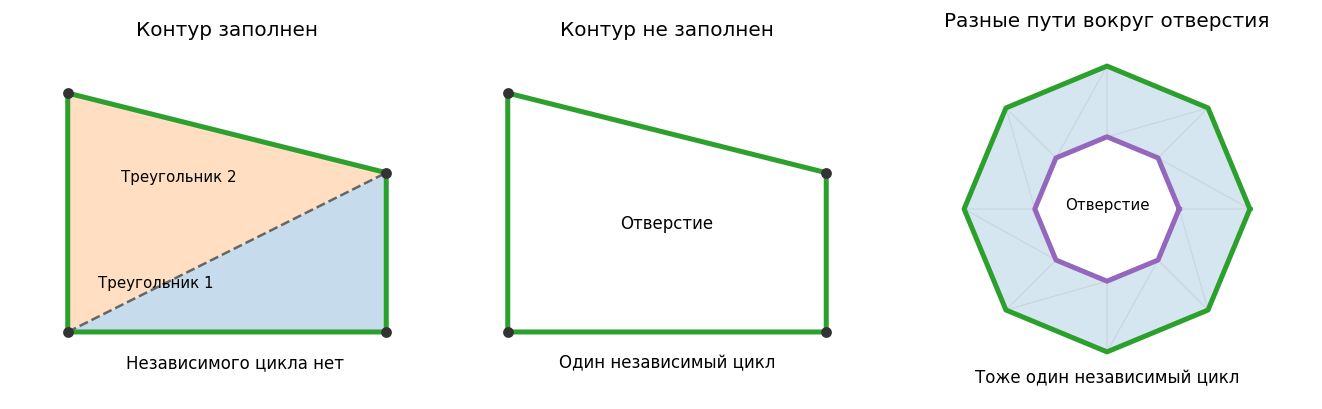

In [6]:
quad = np.array([[0., 0.], [2., 0.], [2., 1.], [0., 1.5]])
fig, axes = plt.subplots(1, 3, figsize=(11, 3.3), layout="constrained")
for ax in axes:
    ax.set(aspect="equal", xlim=(-.35, 2.35), ylim=(-.35, 1.8), xticks=[], yticks=[])
    for spine in ax.spines.values():
        spine.set_visible(False)

ax = axes[0]
ax.add_collection(PolyCollection([quad[[0, 1, 2]], quad[[0, 2, 3]]],
                                 facecolors=["C0", "C1"], alpha=.25))
path = np.vstack((quad, quad[0]))
ax.plot(*path.T, color="C2", lw=3)
ax.plot(*quad[[0, 2]].T, "--", color="0.4")
ax.scatter(*quad.T, color="0.2", s=30, zorder=3)
ax.set_title("Контур заполнен")
ax.text(.55, .28, "Треугольник 1", ha="center", fontsize=9)
ax.text(.7, .95, "Треугольник 2", ha="center", fontsize=9)
ax.text(1.05, -.22, "Независимого цикла нет", ha="center", fontsize=10)

ax = axes[1]
ax.plot(*path.T, color="C2", lw=3)
ax.scatter(*quad.T, color="0.2", s=30, zorder=3)
ax.text(1, .65, "Отверстие", ha="center")
ax.set_title("Контур не заполнен")
ax.text(1, -.22, "Один независимый цикл", ha="center", fontsize=10)

ax = axes[2]
a = np.arange(8)*2*np.pi/8
center = np.array([1., .65])
outer = center + np.column_stack((np.cos(a), np.sin(a)))*.95
inner = center + np.column_stack((np.cos(a), np.sin(a)))*.48
faces = []
for i in range(8):
    j = (i+1) % 8
    faces.extend([np.array([outer[i], outer[j], inner[j]]),
                  np.array([outer[i], inner[j], inner[i]])])
ax.add_collection(PolyCollection(faces, facecolors="C0", alpha=.18,
                                 edgecolors="0.7", linewidths=.6))
ax.plot(*np.vstack((outer, outer[0])).T, color="C2", lw=3)
ax.plot(*np.vstack((inner, inner[0])).T, color="C4", lw=3)
ax.set_title("Разные пути вокруг отверстия")
ax.text(1, .65, "Отверстие", ha="center", fontsize=9)
ax.text(1, -.5, "Тоже один независимый цикл", ha="center", fontsize=10)
ax.set_ylim(-.6, 1.8)
show_figure(fig, "05_how_cycles_are_found")

На следующем графике **каждый горизонтальный отрезок соответствует одному циклу**. Его левый конец — расстояние $\epsilon$, при котором цикл появляется; правый — расстояние, при котором он исчезает после заполнения треугольниками.

Два синих отрезка значительно длиннее серых. Выбираем соответствующие два независимых цикла. Красный пунктир — порог $\epsilon$, на котором оба ещё существуют, а короткие уже закончились.

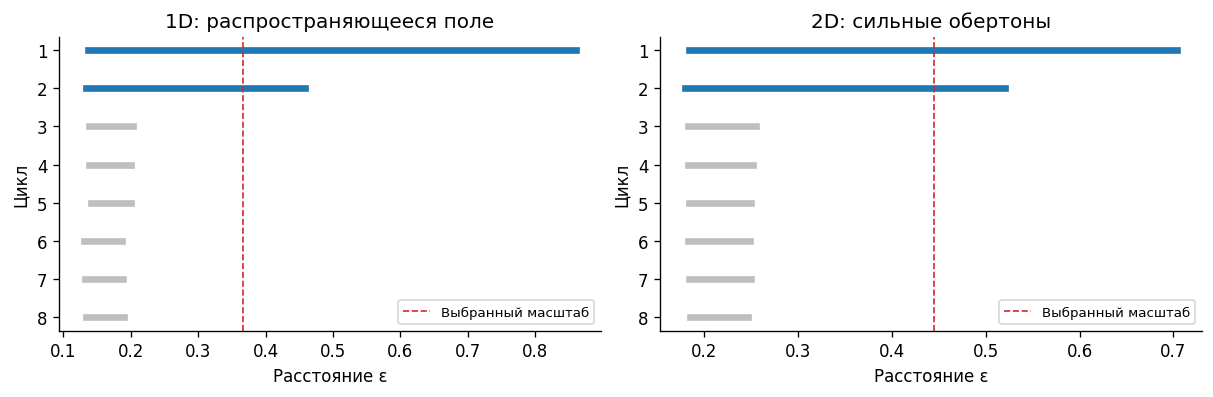

In [7]:
models = {}
for name, label in zip(names, labels):
    model = fit_hankel_topology(blocks[name]["train"]["H"], SETTINGS)
    if model.get("train_phases") is None:
        raise RuntimeError(f"{label}: координаты не построены: {model['diagnostics']}")
    models[name] = model

fig, axes = plt.subplots(1, 2, figsize=(10, 3.2), layout="constrained")
for ax, name, label in zip(axes, names, labels):
    model = models[name]
    diagram = model["h1_diagram"][:8]
    rank = model["diagnostics"]["selected_rank"]
    for i, (birth, death) in enumerate(diagram):
        ax.plot([birth, death], [i+1, i+1], lw=4,
                color="C0" if i < rank else "0.75")
    ax.axvline(model["rips_threshold"], color="C3", ls="--",
               lw=1, label="Выбранный масштаб")
    ax.set(title=label, xlabel="Расстояние ε", ylabel="Цикл",
           yticks=np.arange(1, len(diagram)+1))
    ax.invert_yaxis()
    ax.legend(fontsize=8)
show_figure(fig, "03_persistent_loops")